# HistGradientBoosting — experimento inicial

**Pregunta del experimento:** ¿qué capacidad predictiva aporta un ensamble de árboles frente a las referencias iniciales? Se estudian los resultados históricos de **220,003 préstamos**: entrenamiento 2007–2014, validación 2015–2016 y prueba 2017–2018.

El modo predeterminado es **consulta**: lee métricas, tablas y figuras publicadas; no abre el CSV original ni entrena modelos. Para reproducir, cambiar `REPRODUCIR = True` y ejecutar en orden. Esa opción sí carga datos y ejecuta las 108 configuraciones; nunca se activa por abrir el notebook. Las nuevas salidas se guardan en carpetas independientes. Las probabilidades de esta etapa inicial no sustituyen la calibración del flujo final.

## 1. Configuración inicial del entorno

Localizamos la raíz desde el directorio actual o `PROYECTO_ML_RAIZ` y añadimos una sola vez su ruta a `sys.path`. La misma celda funciona desde la raíz y desde `notebooks/`. Los módulos compartidos mantienen el muestreo y los cortes; el módulo del modelo conserva su preparación específica.

In [ ]:
from pathlib import Path
import json
import os
import sys
import time
from math import prod

base = Path(os.environ.get("PROYECTO_ML_RAIZ", Path.cwd())).resolve()
RAIZ = next((p for p in [base, *base.parents] if (p / "src/config.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra Jupyter dentro del proyecto o defina PROYECTO_ML_RAIZ.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from src.comparabilidad_muestra import verificar_muestra
from src.experimento_inicial import (
    LOGISTICAS, cargar_experimento_inicial, cargar_referencias,
    comprobar_predictoras, leer_json, validar_referencias,
)
from src.experimentos import ESCENARIOS, preparar_experimentos, entrenar_experimentos
from src.evaluate import guardar_metricas, tabla_metricas
from src.config import ANIO_CORTE_PRUEBA, ANIO_CORTE_VALIDACION, SEMILLA
from src import arbol as modelo_arbol
from src import boosting as modelo
from src import visualizacion_boosting as figuras

MODO_BUSQUEDA = "completo"


Modo: consulta de evidencia guardada


### Control de ejecución: consulta o reproducción

`REPRODUCIR = False` permite consultar las tablas, configuraciones y figuras históricas sin abrir el CSV original, entrenar, buscar hiperparámetros ni recalibrar. Si falta evidencia se indica el archivo o la sección ausente; no se inicia un entrenamiento para reemplazarla.

Con `REPRODUCIR = True`, reinicia el kernel y ejecuta todas las celdas en orden. Se conserva el experimento original, con sus periodos, semillas y preparación. `RUTA_DATOS = None` utiliza el localizador del proyecto; también puedes indicar la ruta al archivo CSV o CSV.gz, no a su carpeta. Cambiar un valor no ejecuta nada por sí solo.

Las métricas y figuras nuevas se guardan exclusivamente en `outputs/reproducciones/`, en una carpeta fechada de este notebook. La sección final compara la nueva evidencia con los archivos históricos, sin reemplazarlos. Las conclusiones académicas conservan la interpretación histórica; las tablas de reproducción y verificación muestran cualquier discrepancia de la nueva sesión.

`MODO_BUSQUEDA = "completo"` repite las **108 configuraciones**. El modo `"prueba"` ejecuta una configuración con las mismas observaciones y se marca como reproducción incompleta.

In [ ]:
REPRODUCIR = False
RUTA_DATOS = None

In [ ]:
from src.reproduccion_notebooks import SesionNotebook
import json
sesion = SesionNotebook(RAIZ, '03_boosting', REPRODUCIR, RUTA_DATOS)
BASE_REPRODUCCIONES = sesion.base
ORIGEN = RAIZ / "outputs" / 'gradient_boosting_220000'
SALIDA = sesion.salida if REPRODUCIR else ORIGEN
def exigir_reproduccion():
    if not REPRODUCIR:
        raise RuntimeError("Esta operación requiere REPRODUCIR = True.")
    if not sesion.reproducir:
        raise RuntimeError("Reinicia el kernel y ejecuta desde el principio para reproducir.")
    sesion.exigir()
    if SALIDA != sesion.salida:
        raise RuntimeError("Reinicia el kernel: no cambies el destino a una carpeta histórica.")
PARES_VERIFICACION = [
    (RAIZ / "outputs" / 'gradient_boosting_220000/metrics_boosting.json', SALIDA / 'experimento/metrics_boosting.json'),
    (RAIZ / "outputs" / 'gradient_boosting_220000/busqueda_boosting.csv', SALIDA / 'experimento/busqueda_boosting.csv'),
    (RAIZ / "outputs" / 'gradient_boosting_220000/importancia_boosting.csv', SALIDA / 'experimento/importancia_boosting.csv'),
    (RAIZ / "outputs" / 'gradient_boosting_220000/muestra_verificada.json', SALIDA / 'experimento/muestra_verificada.json'),
]
sesion.requerir([a for a, _ in PARES_VERIFICACION if a.is_file()])
CARPETA_MODELO = SALIDA / "experimento" if REPRODUCIR else SALIDA
FIGURAS = SALIDA / "figuras" if REPRODUCIR else RAIZ / "reports/figures/gradient_boosting_220000"

## 2. Carga de datos, muestra y particiones

Ambos notebooks invocan `cargar_experimento_inicial`. En consulta, la tabla procede de `outputs/auditoria.json`: no se presentan como cargadas unas observaciones que no están en memoria. En reproducción, la función llama **una sola vez** a `escanear_y_muestrear` y después a `dividir_por_anio`.

Se conserva la receta histórica: estados exactos `Fully Paid`/`Charged Off`, semilla 42, bloques de 50,000, fracción aleatoria común sin reemplazo y semilla `42 + índice_de_bloque`, empezando el índice en cero. El objetivo es 220,000; el redondeo por bloque produce 220,003 y **no se recorta**. Los cortes son 2015 y 2017. La tasa se refiere a `Charged Off = 1` y no se equilibran artificialmente las clases.

In [2]:
if REPRODUCIR:
    exigir_reproduccion()
experimento = cargar_experimento_inicial(
    ruta_datos=RUTA_DATOS,
    modo="reproduccion" if REPRODUCIR else "consulta", raiz=RAIZ, verbose=REPRODUCIR
)
referencias = cargar_referencias(RAIZ)
validar_referencias(experimento, [referencias["logistica"], referencias["arbol"]])
display(experimento["resumen"])
print("Tamaño efectivo:", int(experimento["resumen"]["filas"].sum()))
print("Origen:", "CSV original" if REPRODUCIR else "auditoría histórica; CSV no cargado")

,filas,tasa_incumplimiento,periodo
entrenamiento,73701,0.168682,2007–2014
validacion,109382,0.213445,2015–2016
prueba,36920,0.212459,2017–2018


Tamaño efectivo: 220003
Origen: auditoría histórica; CSV no cargado


## 3. Preparación específica de variables

Se excluyen identificadores, texto fuera de alcance, datos posteriores al otorgamiento y precio/calificación de Lending Club. El filtro de más de 95% de faltantes se aprende solo en entrenamiento; quedan 65 características originales. La antigüedad crediticia se prepara con las funciones existentes y las alertas de calidad no eliminan automáticamente filas.

Las numéricas conservan sus `NaN` para el tratamiento nativo del clasificador y **no se escalan**. Las categóricas se rellenan con «Sin información» y se codifican con One-Hot completo, `min_frequency=0.005` y manejo de categorías desconocidas. El codificador se ajusta solo con entrenamiento. La logística utiliza otra preparación: mediana, escalado, categoría de referencia y, en la variante adicional, 31 indicadores. Por eso la comparación mide rendimiento de estrategias completas, no exclusivamente el algoritmo.

En consulta mostramos la metadata guardada. En reproducción construimos las matrices una vez y se las pasamos al ejecutor, que reutiliza las particiones de la sección anterior.

In [3]:
registro = referencias["boosting"]
if REPRODUCIR:
    exigir_reproduccion()
    datos = modelo.preparar_datos(
        experimento["particiones"], experimento["columnas_vacias"], incluir_precio_lc=False
    )
    comprobar_predictoras(datos, RAIZ)
    display(pd.Series(datos["variables"], name="preparación actual"))
else:
    datos = None
    display(pd.Series(registro["variables"], name="preparación histórica"))

predictoras_evaluadas       95
predictoras_finales         65
columnas_modelo            127
excluidas_por_faltantes     30
Name: preparación histórica, dtype: int64

## 4. Modelo inicial y comportamiento de referencia

La logística sin indicadores es el baseline sencillo; la variante con indicadores es una comparación adicional con mayor ROC-AUC de validación. Sus métricas se leen de `outputs/metrics.json`, sin volver a ajustarlas. La igualdad de receta, periodos, tamaños y tasas se controla, pero no se simulan probabilidades individuales a partir de AUC.

El árbol elegido aporta una referencia no lineal ya medida. No introducimos una configuración inicial nueva del ensamble: las referencias se fijaron antes de la grilla. La clase mayoritaria ilustra que una accuracy elevada por desbalance no garantiza detectar incumplimientos.

In [4]:
filas_referencia = []
for nombre in LOGISTICAS:
    m = referencias["logistica"]["resultados"][nombre]["validacion"]
    filas_referencia.append({"modelo": nombre, "ROC-AUC validación": m["roc_auc"],
                             "PR-AUC validación": m["pr_auc"], "fuente": "outputs/metrics.json"})
display(pd.DataFrame(filas_referencia).round(6))
display(tabla_metricas({"arbol_elegido": referencias["arbol"]["resultados"]["arbol_elegido"]}))

,modelo,ROC-AUC validación,PR-AUC validación,fuente
0,logistica_sin_indicadores,0.712053,0.401609,outputs/metrics.json
1,logistica_con_indicadores,0.712758,0.402534,outputs/metrics.json


,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy
0,arbol_elegido,entrenamiento,73701,0.6870,0.2980,0.2693,0.6446,0.2584,0.3689,0.6280
1,arbol_elegido,validacion,109382,0.6745,0.3548,0.2486,0.6179,0.3123,0.4149,0.6280
2,arbol_elegido,prueba,36920,0.6346,0.3070,0.1895,0.5483,0.2865,0.3763,0.6139


## 5. Búsqueda de hiperparámetros

La grilla original contiene **108** combinaciones: `learning_rate=[0.03, 0.05, 0.1]`, `max_iter=[100, 200]`, `max_leaf_nodes=[15, 31, 63]`, `min_samples_leaf=[20, 100]` y `max_depth=[5, 8, None]`. Se mantiene semilla 42 y `early_stopping=False`. El criterio es ROC-AUC de validación y la brecha entrenamiento–validación resuelve empates.

Al reproducir, `verificar_muestra()` reconstruye de forma independiente IDs, estados y fechas usando solo esas columnas. Es un control adicional de identidades, **no otro conjunto de entrenamiento** ni una segunda llamada al muestreador de datos completos. Se conserva su límite: las métricas históricas no incluyen IDs para demostrar identidad fila a fila con todas las ejecuciones pasadas.

**Hiperparámetros y umbral son decisiones distintas:** los primeros se eligen por ROC-AUC de validación; después se elige el umbral que maximiza F1 con esa validación mediante `elegir_umbral`. La prueba no selecciona ninguno de los dos. En consulta se leen la grilla y los resultados guardados; solo el bloque `if REPRODUCIR` inicia ajustes.

In [5]:
display(pd.Series(modelo.GRILLA, name="valores explorados"))
print("Configuraciones completas:", prod(map(len, modelo.GRILLA.values())))
if REPRODUCIR:
    exigir_reproduccion()
    if MODO_BUSQUEDA not in ["completo", "prueba"]:
        raise ValueError("MODO_BUSQUEDA debe ser 'completo' o 'prueba'.")
    inicio = time.perf_counter()
    manifiesto_muestra = verificar_muestra(
        experimento["ruta"], experimento["muestra"], experimento["auditoria"], 220000,
        [referencias["logistica"], referencias["arbol"]])
    print(f"Muestra verificada: {len(experimento['muestra']):,} préstamos.")

    print("\nReentrenando las referencias logísticas originales...")
    escenarios_logisticos = [e for e in ESCENARIOS if e[0] in LOGISTICAS]
    preparados_logisticos = preparar_experimentos(
        experimento["particiones"], experimento["columnas_vacias"],
        escenarios=escenarios_logisticos)
    resultados_logisticos, modelos_logisticos, puntuaciones_logisticas = entrenar_experimentos(
        preparados_logisticos)
    resultados = {nombre: resultados_logisticos[nombre] for nombre in
                  ["clase_mayoritaria", *LOGISTICAS]}

    print("\nReentrenando el árbol elegido con sus parámetros históricos...")
    datos_arbol = modelo_arbol.preparar_datos(
        experimento["particiones"], experimento["columnas_vacias"], incluir_precio_lc=False)
    comprobar_predictoras(datos_arbol, RAIZ)
    parametros_arbol_guardados = referencias["arbol"]["parametros_elegidos"]
    parametros_arbol = {
        k: None if v in [None, "None"] else v if k == "class_weight" else int(v)
        for k, v in parametros_arbol_guardados.items()
    }
    arbol_entrenado, puntuaciones_arbol, metricas_arbol = modelo_arbol.entrenar_y_evaluar(
        datos_arbol, parametros_arbol)
    resultados["arbol_elegido"] = metricas_arbol

    grilla = (modelo.GRILLA if MODO_BUSQUEDA == "completo"
              else {k: [v[0]] for k, v in modelo.GRILLA.items()})
    print(f"Búsqueda {MODO_BUSQUEDA}: {prod(map(len, grilla.values()))} configuraciones.")
    print("Memoria de matrices GB (MiB):",
          {k: round(x.nbytes / 1024**2, 1) for k, x in datos["X"].items()})
    busqueda = modelo.buscar_hiperparametros(datos, grilla=grilla)
    parametros = modelo.parametros_de_fila(busqueda.iloc[0])
    modelo_boosting, puntuaciones, metricas = modelo.entrenar_y_evaluar(datos, parametros)
    resultados["gradient_boosting_base"] = metricas
    importancia = modelo.importancia_por_permutacion(datos, modelo_boosting)

    CARPETA_MODELO.mkdir(parents=True, exist_ok=True)
    FIGURAS.mkdir(parents=True, exist_ok=True)
    busqueda.to_csv(CARPETA_MODELO / "busqueda_boosting.csv", index=False)
    importancia.to_csv(CARPETA_MODELO / "importancia_boosting.csv", index=False)
    (CARPETA_MODELO / "muestra_verificada.json").write_text(
        json.dumps(manifiesto_muestra, ensure_ascii=False, indent=2), encoding="utf-8")
    guardar_metricas(resultados, CARPETA_MODELO / "metrics_boosting.json", extra={
        "semilla": SEMILLA,
        "tamano_muestra_objetivo": 220000,
        "filas_muestra": len(experimento["muestra"]),
        "modo": MODO_BUSQUEDA,
        "cortes": {"validacion": ANIO_CORTE_VALIDACION,
                   "prueba": ANIO_CORTE_PRUEBA},
        "grilla": grilla,
        "parametros_elegidos": parametros,
        "parametros_arbol_fijados": parametros_arbol,
        "variables": datos["variables"],
        "criterio_seleccion": "máximo ROC-AUC de validación; test solo después de fijar parámetros",
        "origen_metricas": {
            **{n: "referencia reentrenada en esta reproducción" for n in
               [*LOGISTICAS, "clase_mayoritaria", "arbol_elegido"]},
            "gradient_boosting_base": "reproducción actual",
        },
        "alcance_tiempo": "incluye reentrenamiento de referencias y búsqueda; excluye carga de datos y preparación de matrices",
        "segundos_totales": time.perf_counter() - inicio,
    })

    curvas = [("Gradient Boosting elegido", datos["y"]["validacion"],
               puntuaciones["validacion"])]
    figuras.fig_busqueda(
        busqueda, resultados["logistica_sin_indicadores"]["validacion"]["roc_auc"],
        salida=FIGURAS)
    figuras.fig_importancia(importancia, salida=FIGURAS)
    referencias_auc = {nombre: resultados[nombre]["validacion"]["roc_auc"]
                       for nombre in [*LOGISTICAS, "arbol_elegido"]}
    figuras.fig_roc_comparacion(curvas, salida=FIGURAS,
                                referencias_auc=referencias_auc)
    registro = leer_json(CARPETA_MODELO / "metrics_boosting.json")
    print(tabla_metricas(resultados).to_string(index=False))
    print("Métricas:", CARPETA_MODELO, "Figuras:", FIGURAS)
    print(f"Tiempo de ajuste y búsqueda: {time.perf_counter() - inicio:.0f}s")

busqueda = pd.read_csv(CARPETA_MODELO / "busqueda_boosting.csv")
print("Parámetros elegidos:", registro["parametros_elegidos"])
display(busqueda.head(10).round(6))


learning_rate       [0.03, 0.05, 0.1]
max_iter                   [100, 200]
max_leaf_nodes           [15, 31, 63]
min_samples_leaf            [20, 100]
max_depth                [5, 8, None]
Name: valores explorados, dtype: object

Configuraciones completas: 108
Parámetros elegidos: {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'max_depth': 8}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,max_depth,auc_entrenamiento,auc_validacion,n_iteraciones,brecha
0,0.05,200,15,100,8.0,0.748146,0.715564,200,0.032582
1,0.05,200,31,100,8.0,0.787858,0.715357,200,0.072500
2,0.05,200,31,100,NaN,0.791281,0.715334,200,0.075947
3,0.05,200,15,100,NaN,0.748450,0.715310,200,0.033140
4,0.05,200,15,100,5.0,0.745614,0.715025,200,0.030589
5,0.10,100,15,100,8.0,0.746574,0.714868,100,0.031706
6,0.05,200,31,20,8.0,0.795289,0.714831,200,0.080458
7,0.03,200,63,100,NaN,0.813109,0.714721,200,0.098388
8,0.05,200,15,20,NaN,0.751452,0.714698,200,0.036754
9,0.10,200,15,100,8.0,0.777911,0.714694,200,0.063217


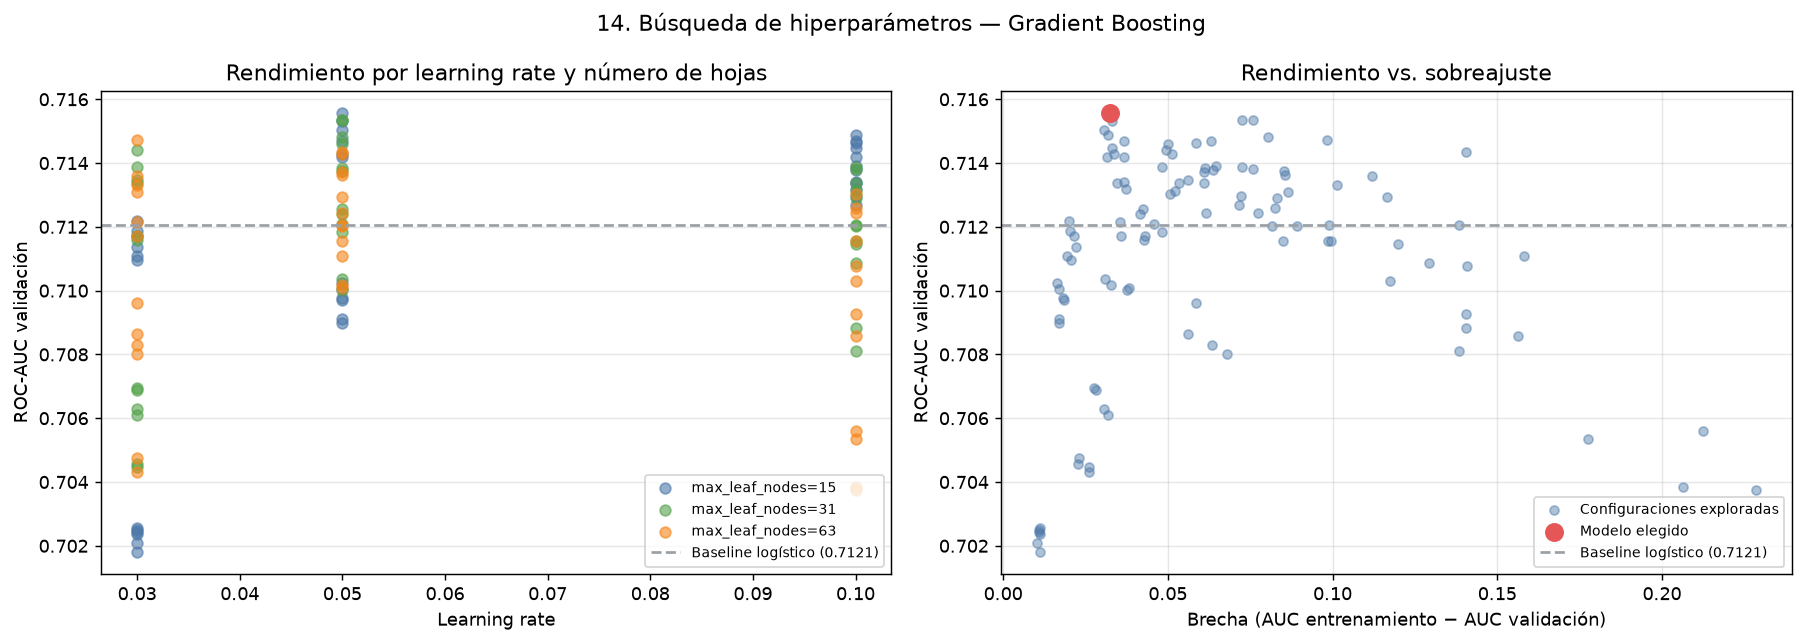

In [6]:
display(Image(filename=str(FIGURAS / "14_boosting_busqueda.png")))

La figura contrasta rendimiento y brecha de ajuste entre las configuraciones probadas. La combinación elegida maximiza el criterio de validación; no garantiza un óptimo universal ni una mejora significativa. El tiempo registrado corresponde a su ejecución y equipo, no a una nueva medición en este notebook de consulta.

## 6. Evaluación y comparación

Se muestran primero entrenamiento y validación; la prueba se presenta después de fijar la configuración. ROC-AUC y Average Precision utilizan puntuaciones continuas, mientras F1, precisión y recall dependen del umbral elegido. Las dos logísticas proceden de sus métricas guardadas; no se atribuye su resultado a un reentrenamiento en esta sesión. Se identifica la procedencia de cada fila.

In [7]:
resultados = dict(registro["resultados"])
for nombre in LOGISTICAS:
    resultados[nombre] = referencias["logistica"]["resultados"][nombre]
tabla = tabla_metricas(resultados)
for i, fila in tabla.iterrows():
    tabla.loc[i, "ROC-AUC"] = resultados[fila["modelo"]][fila["conjunto"]]["roc_auc"]
    tabla.loc[i, "PR-AUC"] = resultados[fila["modelo"]][fila["conjunto"]]["pr_auc"]
tabla["origen"] = tabla["modelo"].map(
    lambda nombre: "referencia logística guardada" if nombre in LOGISTICAS
    else registro.get("origen_metricas", {}).get(nombre, "ejecución histórica guardada")
)
display(tabla[tabla["conjunto"].isin(["entrenamiento", "validacion"])].round(6))
comparacion = tabla[tabla["conjunto"] == "validacion"].copy()
base = resultados["logistica_sin_indicadores"]["validacion"]["roc_auc"]
comparacion["diferencia_ROC_AUC_vs_baseline"] = comparacion["ROC-AUC"] - base
display(comparacion.round(6))

,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy,origen
0,logistica_sin_indicadores,entrenamiento,73701,0.702498,0.323402,0.2966,0.6172,0.2773,0.3827,0.6641,referencia logística guardada
1,logistica_sin_indicadores,validacion,109382,0.712053,0.401609,0.3071,0.6344,0.3440,0.4461,0.6637,referencia logística guardada
3,clase_mayoritaria,entrenamiento,73701,0.500000,0.168682,0.0000,0.0000,0.0000,0.0000,0.8313,ejecución histórica guardada
4,clase_mayoritaria,validacion,109382,0.500000,0.213445,0.0000,0.0000,0.0000,0.0000,0.7866,ejecución histórica guardada
6,arbol_elegido,entrenamiento,73701,0.686976,0.297992,0.2693,0.6446,0.2584,0.3689,0.6280,ejecución histórica guardada
7,arbol_elegido,validacion,109382,0.674482,0.354819,0.2486,0.6179,0.3123,0.4149,0.6280,ejecución histórica guardada
9,gradient_boosting_base,entrenamiento,73701,0.748146,0.391956,0.3653,0.6468,0.3157,0.4243,0.7040,ejecución histórica guardada
10,gradient_boosting_base,validacion,109382,0.715564,0.407159,0.3123,0.6065,0.3561,0.4487,0.6819,ejecución histórica guardada
12,logistica_con_indicadores,entrenamiento,73701,0.703144,0.324147,0.2958,0.6271,0.2758,0.3831,0.6594,referencia logística guardada
13,logistica_con_indicadores,validacion,109382,0.712758,0.402534,0.3079,0.6495,0.3403,0.4466,0.6564,referencia logística guardada


,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy,origen,diferencia_ROC_AUC_vs_baseline
1,logistica_sin_indicadores,validacion,109382,0.712053,0.401609,0.3071,0.6344,0.3440,0.4461,0.6637,referencia logística guardada,0.000000
4,clase_mayoritaria,validacion,109382,0.500000,0.213445,0.0000,0.0000,0.0000,0.0000,0.7866,ejecución histórica guardada,-0.212053
7,arbol_elegido,validacion,109382,0.674482,0.354819,0.2486,0.6179,0.3123,0.4149,0.6280,ejecución histórica guardada,-0.037571
10,gradient_boosting_base,validacion,109382,0.715564,0.407159,0.3123,0.6065,0.3561,0.4487,0.6819,ejecución histórica guardada,0.003511
13,logistica_con_indicadores,validacion,109382,0.712758,0.402534,0.3079,0.6495,0.3403,0.4466,0.6564,referencia logística guardada,0.000705


,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy,origen
2,logistica_sin_indicadores,prueba,36920,0.690191,0.358399,0.2825,0.5764,0.3348,0.4235,0.6667,referencia logística guardada
5,clase_mayoritaria,prueba,36920,0.500000,0.212459,0.0000,0.0000,0.0000,0.0000,0.7875,ejecución histórica guardada
8,arbol_elegido,prueba,36920,0.634576,0.306990,0.1895,0.5483,0.2865,0.3763,0.6139,ejecución histórica guardada
11,gradient_boosting_base,prueba,36920,0.691355,0.363009,0.2757,0.5335,0.3436,0.4180,0.6844,ejecución histórica guardada
14,logistica_con_indicadores,prueba,36920,0.692175,0.361011,0.2864,0.5917,0.3330,0.4262,0.6615,referencia logística guardada


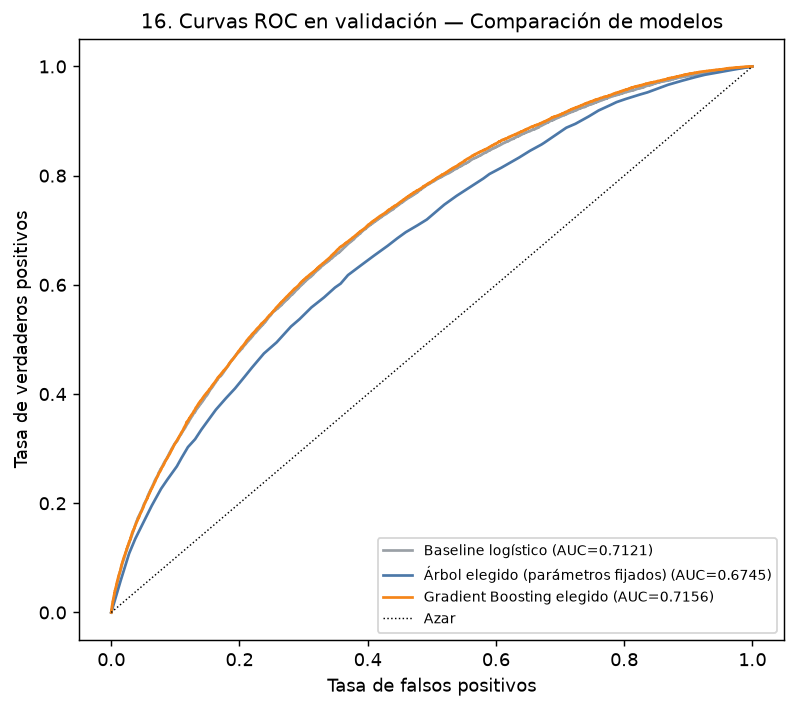

In [8]:
display(tabla[tabla["conjunto"] == "prueba"].round(6))
display(Image(filename=str(FIGURAS / "16_boosting_comparacion_roc.png")))

La curva histórica conserva los modelos para los que se guardó esa figura; no contiene una curva de la logística con indicadores. No se reconstruyen curvas desde métricas agregadas. Para incluir esa variante harían falta sus puntuaciones individuales y etiquetas alineadas, no disponibles en los outputs publicados. Una nueva reproducción dibuja solo curvas con scores recién obtenidos y anota las AUC guardadas como texto; nunca las presenta como curvas nuevas de referencia.

Las 65 características originales coinciden, pero la logística con indicadores agrega 31 columnas y utiliza otras transformaciones. Por ello no se interpreta una diferencia como efecto aislado del algoritmo. El periodo de prueba ya fue consultado históricamente: no constituye una evaluación prospectiva completamente desconocida.

## 7. Interpretación e importancia de variables

Se consulta la importancia por permutación del ensamble elegido, calculada sobre hasta 30,000 observaciones de validación y cinco repeticiones. La caída de ROC-AUC al desordenar una variable mide utilidad en ese modelo; no es una explicación causal ni la importancia del modelo final calibrado.

Una importancia cercana a cero puede reflejar redundancia o la estructura aprendida; no demuestra irrelevancia universal. La importancia de Gini y la permutación miden propiedades diferentes y ninguna acredita equidad por sí sola.

,variable,caida_auc_media,caida_auc_desv
0,term,0.058488,0.000582
1,loan_amnt,0.016196,0.000531
2,fico_range_low,0.014688,0.000923
3,annual_inc,0.013515,0.001042
4,acc_open_past_24mths,0.007850,0.001231
5,dti,0.007057,0.000615
6,num_tl_op_past_12m,0.004504,0.000470
7,purpose,0.003945,0.000509
8,emp_length,0.002947,0.000263
9,total_bc_limit,0.002166,0.000272


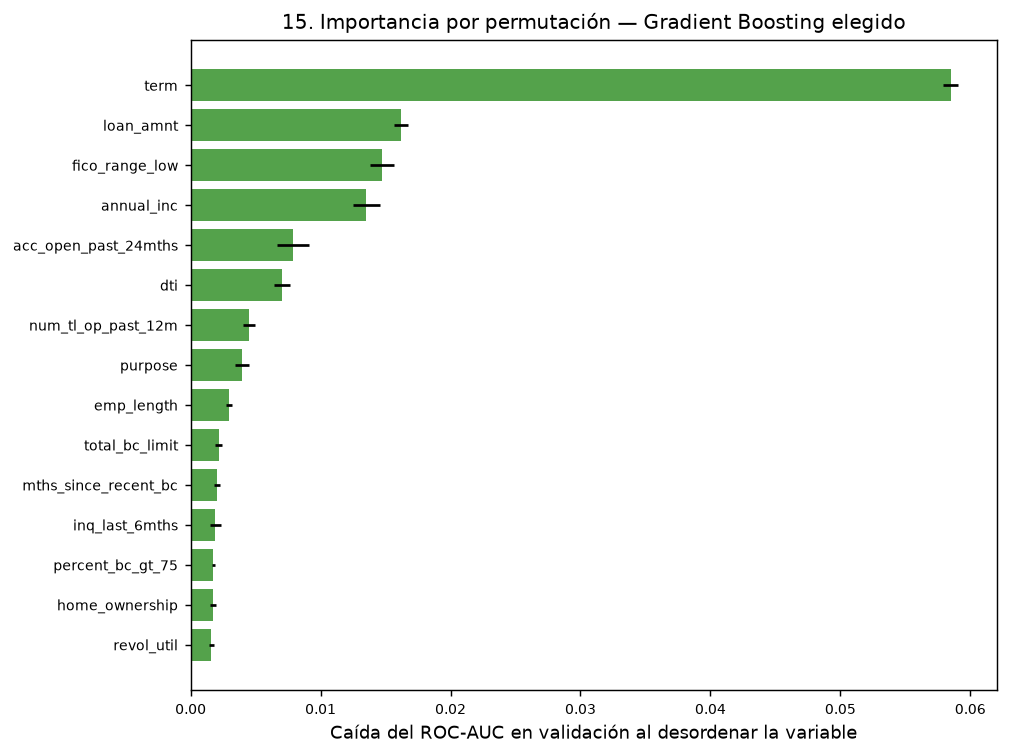

In [9]:
importancia = pd.read_csv(CARPETA_MODELO / "importancia_boosting.csv")
display(importancia.head(15))
display(Image(filename=str(FIGURAS / "15_boosting_importancia.png")))

## 8. Conclusiones

HistGradientBoosting obtuvo ROC-AUC de validación **0.715564**, frente a **0.712053** de la logística sin indicadores, **0.712758** de la variante con indicadores y **0.674482** del árbol. Superó las dos logísticas en validación, con diferencias pequeñas que no prueban significación estadística.

En prueba, su ROC-AUC de aproximadamente **0.691355** queda por encima de la logística sin indicadores (**0.690191**), pero por debajo de la variante con indicadores (**0.692175**). No hay un ganador uniforme en todas las comparaciones. Las características y transformaciones difieren entre estrategias; las probabilidades iniciales no han pasado por la calibración posterior del proyecto final.

Estas conclusiones describen la ejecución histórica publicada. Si se activa reproducción, las salidas nuevas conservan su procedencia y deben revisarse por separado; ejecutar el modo consulta no demuestra una nueva reproducción numérica.

## 9. Reproducción del experimento

Con `REPRODUCIR = False`, el notebook consulta las métricas, tablas y figuras históricas sin abrir el CSV ni ajustar modelos. Para repetirlo, cambia a `True`, indica `RUTA_DATOS` solo si el archivo está fuera de las ubicaciones habituales, reinicia el kernel y ejecuta todas las celdas en orden.

En reproducción se reconstruye una sola muestra objetivo de 220,000 préstamos; el redondeo histórico deja 220,003. La sección 2 verifica sus particiones temporales. En la sección 3 se prepara una vez la matriz de Gradient Boosting. La sección 5 vuelve a ajustar las dos referencias logísticas y el árbol con su configuración histórica; las configuraciones y cortes no se buscan de nuevo para esos modelos. Luego ejecuta Gradient Boosting y guarda métricas, tablas, muestra verificada y tres figuras dentro de una carpeta exclusiva de `outputs/reproducciones/`. Las referencias oficiales no se sobrescriben.

`MODO_BUSQUEDA = "completo"` ejecuta las 108 configuraciones originales. `MODO_BUSQUEDA = "prueba"` ejecuta solo una configuración para comprobar el flujo; se registra como reproducción incompleta y no sustituye la búsqueda completa. Las funciones del modelo están en `src/boosting.py`, las del árbol en `src/arbol.py` y las gráficas en `src/visualizacion_boosting.py`. El notebook coordina el experimento sin un ejecutor independiente.


## Verificación de reproducibilidad

La comparación usa los valores guardados sin redondearlos: tolerancia absoluta `1e-8` y relativa `1e-6` para números reales (diferencias de cálculo pequeñas), e igualdad exacta para enteros, etiquetas, años, semillas e hiperparámetros categóricos. Estas tolerancias son controles de reproducción, no pruebas de significación ni garantías ante cambios de bibliotecas.

Las filas CSV se alinean por sus claves metodológicas cuando existen y se comprueba que no estén duplicadas. Los tiempos no tienen que coincidir. Se contrastan los tamaños, decisiones y configuraciones disponibles, además de las métricas; una AUC igual no prueba que se hayan usado las mismas observaciones. Sin evidencia de identidad, se indica **No verificable con la evidencia disponible**. Las figuras se presentan para inspección visual; no se afirma identidad de píxeles.

**Coincide** y **Difiere** requieren una reproducción ejecutada. **No verificado** significa que solo se consultaron resultados. **No verificable** señala una referencia ausente o insuficiente. La consulta nunca se presenta como una reproducción exitosa.

In [ ]:
verificacion = sesion.finalizar(PARES_VERIFICACION, configuracion={'etapa': '03_boosting', 'semilla': 42, 'muestra_objetivo': 220000, 'muestra_historica_efectiva': 220003, 'cortes': {'validacion': ANIO_CORTE_VALIDACION, 'prueba': ANIO_CORTE_PRUEBA}, 'modo_busqueda': MODO_BUSQUEDA, 'configuraciones': prod(map(len, grilla.values())) if REPRODUCIR else prod(map(len, modelo.GRILLA.values()))}, datos=experimento["ruta"] if REPRODUCIR else None, completa=(MODO_BUSQUEDA == "completo"))
display(verificacion)
print("Resumen de verificación:", verificacion["Estado"].value_counts().to_dict())